# WEEK 5 contest: baseline solution (MLP and a simple CNN)

**Task:** classify aerial / satellite images (256×256 px) into **20 scene classes**.

In order to start you need to download .zip file from Kaggle with all the folders organized for this contest. You can use this link, but remember it will be avialable only ~1 WEEK (don't forget to uncomment it).

In [1]:
!gdown 1sbnKeVmiOmT4ZZHIbXIxuBWF9CQLWt6s

Downloading...
From (original): https://drive.google.com/uc?id=1sbnKeVmiOmT4ZZHIbXIxuBWF9CQLWt6s
From (redirected): https://drive.google.com/uc?id=1sbnKeVmiOmT4ZZHIbXIxuBWF9CQLWt6s&confirm=t&uuid=b05de6d8-2af1-4743-8fc2-5236b1517794
To: /content/week-5-competition-geo-satellites-classification.zip
100% 305M/305M [00:01<00:00, 269MB/s]


Next we need to unzip our archive with subsets...

In [2]:
from IPython.display import clear_output

In [3]:
!unzip week-5-competition-geo-satellites-classification.zip
clear_output()

**The data**
```
train/  val/  test/          images, e.g. train/1000.jpg
train.csv, val.csv           id,label     (id = image file name, label = 0...19)
test.csv                     id           (the images you have to classify)
classes.csv                  label,class_name
sample_submission_example    example for the Kaggle submission
```
The training set is small (250 images per class) and the test set is larger, as in many real projects where
labelled data is expensive. The validation and test images come from the same distribution. Compare them carefully
with the training images.

**Plan of this notebook**
1. Setup
2. Read the CSV files
3. Transformations and augmentations with `transforms.Compose`
4. A `Dataset` that reads images from the folders
5. Training and evaluation functions
6. Model 1: MLP (with loss and accuracy graphs)
7. Model 2: a simple CNN (with loss and accuracy graphs)
8. Design your own CNN
9. Compare the models
10. Predict the test images and create `submission.csv`
11. Upload to Kaggle
12. **Assignment:** pretrained models and a confusion matrix

**Scoring:** Accuracy, the share of test images classified correctly. All classes have the same number of images,
so accuracy treats every class equally.

To run it with a GPU (Colab: *Runtime → Change runtime type → T4 GPU*).

## 1. Setup
Set `DATA_DIR` to the folder that contains `train/`, `val/`, `test/` and the CSV files
(on Kaggle: `/kaggle/input/<competition-name>`).

**Reproducibility (contest rule):** keep `SEED` fixed and call `seed_everything()` before training, so
re-running the notebook gives the same result.

In [4]:
import os
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

DATA_DIR = Path(os.environ.get("CONTEST_DATA", "/content/"))
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
print("device:", DEVICE)
print("data folder:", sorted(p.name for p in DATA_DIR.iterdir()))

device: cuda
data folder: ['.config', 'classes.csv', 'sample_data', 'sample_submission_example.csv', 'test', 'test.csv', 'train', 'train.csv', 'val', 'val.csv', 'week-5-competition-geo-satellites-classification.zip']


## 2. Read the CSV files

In [5]:
train_table = pd.read_csv(DATA_DIR / "train.csv", dtype={"id": str})
val_table = pd.read_csv(DATA_DIR / "val.csv", dtype={"id": str})
test_table = pd.read_csv(DATA_DIR / "test.csv", dtype={"id": str})
classes = pd.read_csv(DATA_DIR / "classes.csv").sort_values("label").class_name.tolist()
NUM_CLASSES = len(classes)

print(f"train: {len(train_table)} images | val: {len(val_table)} | test: {len(test_table)} | classes: {NUM_CLASSES}")
print(classes)
train_table.head()

train: 4999 images | val: 699 | test: 8299 | classes: 20
['baseball_diamond', 'basketball_court', 'bridge', 'church', 'cloud', 'commercial_area', 'lake', 'medium_residential', 'overpass', 'palace', 'railway', 'railway_station', 'rectangular_farmland', 'roundabout', 'runway', 'sea_ice', 'snowberg', 'tennis_court', 'terrace', 'wetland']


,id,label
0,1.jpg,4
1,3.jpg,11
2,6.jpg,10
3,9.jpg,19
4,10.jpg,7


**Let's look at one training image per class.**

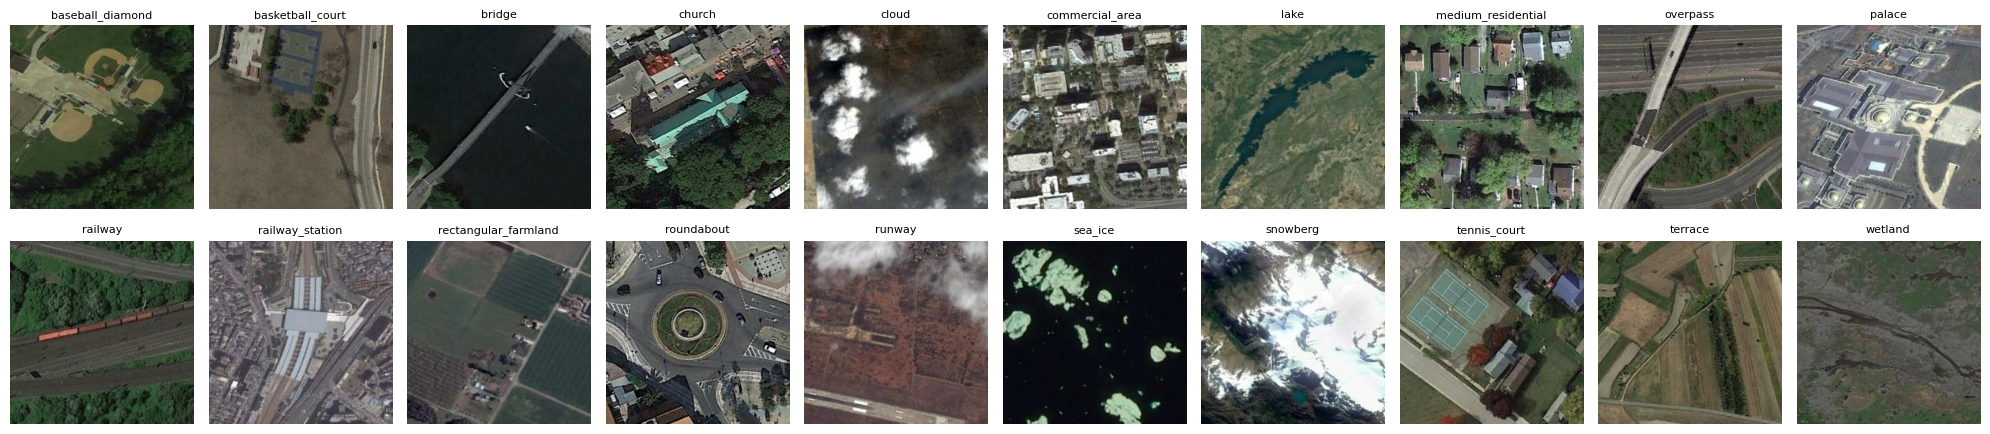

In [6]:
def image_file(folder, image_id):
    """Path of an image. Ids are file names such as '1000.jpg' (plain numbers also work)."""
    name = image_id if image_id.endswith(".jpg") else f"{image_id}.jpg"
    return DATA_DIR / folder / name

cols = (NUM_CLASSES + 1) // 2

fig, axes = plt.subplots(2, cols, figsize=(2 * cols, 4.6))
for label, ax in enumerate(axes.flat):
    ax.axis("off")
    if label < NUM_CLASSES:
        first_id = train_table[train_table.label == label].id.iloc[0]
        ax.imshow(Image.open(image_file("train", first_id)))
        ax.set_title(classes[label], fontsize=8)
plt.tight_layout(); plt.show()

## 3. Transformations and augmentations with `transforms.Compose`

As you might notice the **training set** is smaller comparing with the **test set**. Such cases we can overcome by the help of augmentations. In this lab we will go through some augmentation methods.

`transforms.Compose` contains several transformations; every image passes through them **in order**.

**Training images** get random augmentations, so the model sees a slightly different version of each image in
every epoch and can't simply memorise the training set. For aerial images these make sense:
* **flips and 90° rotations**: a photo taken from above has no "up" direction, so a rotated field is still a field;
* **brightness / contrast changes**: the same place looks different at different times of day.

**Validation and test images** are never augmented: they only get the same conversion to a tensor and the same
normalisation, so the model is evaluated on the images as they really are.

`ToTensor()` turns a picture into a tensor of shape (3, H, W) with values 0...1; `Normalize` then maps them to
about -1...1, which helps training.

In [7]:
IMG_SIZE = 32                                  # small images: fast, and enough for an MLP and a simple CNN
MEAN, STD = (0.5, 0.5, 0.5), (0.5, 0.5, 0.5)

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),                          # mirror left-right, half of the images
    transforms.RandomVerticalFlip(p=0.5),                            # mirror top-bottom, half of the images
    transforms.RandomChoice([transforms.RandomRotation((angle, angle)) # rotate by 0, 90, 180 or 270 degrees
                             for angle in (0, 90, 180, 270)]),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),            # brightness and contrast x0.8 ... x1.2
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_transform = transforms.Compose([         # validation and test: Remeber no augmentation for those parts!!!
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

print(train_transform)

Compose(
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomChoice(
    RandomRotation(degrees=[0.0, 0.0], interpolation=nearest, expand=False, fill=0)
    RandomRotation(degrees=[90.0, 90.0], interpolation=nearest, expand=False, fill=0)
    RandomRotation(degrees=[180.0, 180.0], interpolation=nearest, expand=False, fill=0)
    RandomRotation(degrees=[270.0, 270.0], interpolation=nearest, expand=False, fill=0)
)(p=None)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
)


**What do the augmentations do?** A `Compose` is just a list of steps, so for the preview we can reuse every step
except `ToTensor` and `Normalize` (the last two), and show the same image six times.

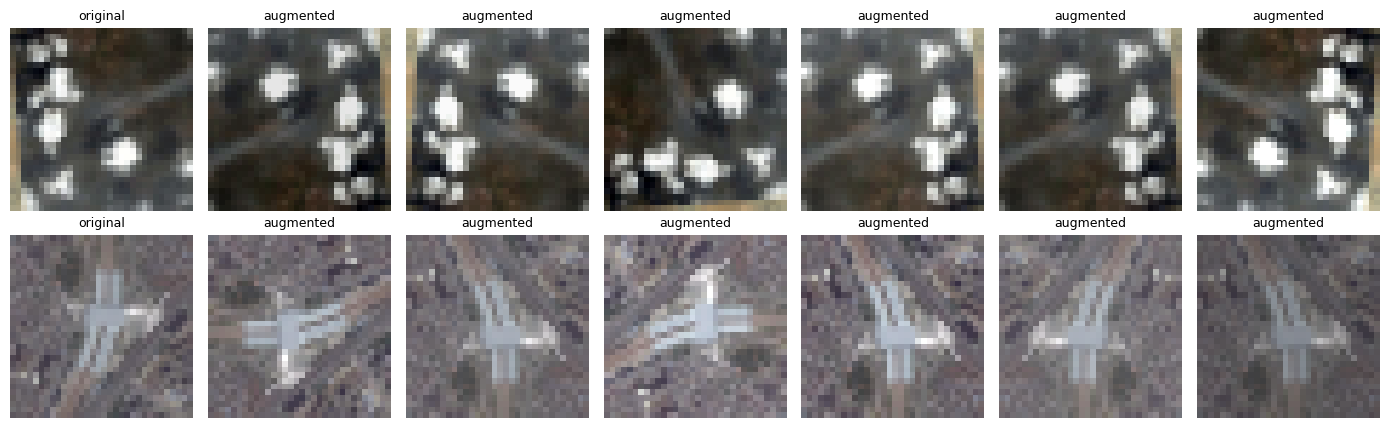

In [8]:
preview_transform = transforms.Compose(train_transform.transforms[:-2])   # augmentations only

fig, axes = plt.subplots(2, 7, figsize=(14, 4.4))
for row, image_id in enumerate(train_table.id.iloc[:2]):
    img = Image.open(image_file("train", image_id)).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BOX)
    axes[row, 0].imshow(img); axes[row, 0].set_title("original", fontsize=9)
    for col in range(1, 7):
        axes[row, col].imshow(preview_transform(img)); axes[row, col].set_title("augmented", fontsize=9)
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

## 4. A `Dataset` that reads images from the folders
A PyTorch `Dataset` answers two questions: *how many samples are there?* (`__len__`) and *what is sample number i?*
(`__getitem__`). Ours reads the ids from a CSV file, loads each image from its folder **once** (resized to
`IMG_SIZE`, kept in memory so training is fast), and applies the transformation every time an image is requested,
so augmentations are different in every epoch.

The test CSV has no labels; for test images the dataset returns the label `-1`.

In [9]:
class ContestDataset(Dataset):
    def __init__(self, table, folder, transform, img_size=IMG_SIZE):
        self.ids = table.id.tolist()
        self.labels = table.label.tolist() if "label" in table.columns else [-1] * len(table)
        self.transform = transform
        self.images = []
        for image_id in tqdm(self.ids, desc=f"loading {folder}"):
            with Image.open(image_file(folder, image_id)) as img:
                self.images.append(img.convert("RGB").resize((img_size, img_size), Image.BOX))

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        return self.transform(self.images[i]), self.labels[i]

train_set = ContestDataset(train_table, "train", train_transform)
val_set = ContestDataset(val_table, "val", eval_transform)
test_set = ContestDataset(test_table, "test", eval_transform)

image, label = train_set[0]
print("one sample:", tuple(image.shape), "| label:", label, f"({classes[label]})")

loading train:   0%|          | 0/4999 [00:00<?, ?it/s]

loading val:   0%|          | 0/699 [00:00<?, ?it/s]

loading test:   0%|          | 0/8299 [00:00<?, ?it/s]

one sample: (3, 32, 32) | label: 4 (cloud)


## 5. Training and evaluation functions
The `DataLoader` groups samples into batches (and shuffles the training set). The same three functions are used for
every model in this notebook, including the pretrained ones in the assignment:

* `evaluate` computes the loss and the accuracy on a dataset (no training, no augmentation);
* `predict` returns the predicted class of every image in a dataset;
* `train_model` trains for a number of epochs. After every epoch it records the **loss** and **accuracy** on the
  training and the validation set, and at the end it goes back to the weights of the **best epoch** (highest
  validation accuracy).
* `make_loader` helps us to preserve order of images to keep reproducibility.

The models return raw scores (logits); `nn.CrossEntropyLoss` applies the softmax internally.

In [10]:
BATCH_SIZE = 64
criterion = nn.CrossEntropyLoss()

def make_loader(dataset, shuffle):
    generator = torch.Generator().manual_seed(SEED)     # fixed shuffling order -> reproducible
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, generator=generator)

@torch.no_grad()
def evaluate(model, dataset):
    model.eval()
    total_loss, correct = 0.0, 0
    for images, labels in make_loader(dataset, shuffle=False):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        outputs = model(images)
        total_loss += criterion(outputs, labels).item() * len(images)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
    return total_loss / len(dataset), correct / len(dataset)

@torch.no_grad()
def predict(model, dataset):
    model.eval()
    predictions = []
    for images, _ in make_loader(dataset, shuffle=False):
        outputs = model(images.to(DEVICE))
        predictions.append(outputs.argmax(dim=1).cpu())
    return torch.cat(predictions).numpy()

def train_model(model, name, epochs=30, lr=1e-3):
    seed_everything()
    model = model.to(DEVICE)
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable, lr=lr)
    train_loader = make_loader(train_set, shuffle=True)

    history, best_acc, best_weights = [], -1.0, None    # -1.0 is just a number to compare with
    for epoch in range(1, epochs + 1):

        # training step (the same as we've learned so far for simpler models)
        model.train()
        total_loss, correct = 0.0, 0
        for images, labels in train_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(images)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_loss, train_acc = total_loss / len(train_set), correct / len(train_set)

        # validation step
        val_loss, val_acc = evaluate(model, val_set)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                        "train_acc": train_acc, "val_acc": val_acc})

        if val_acc > best_acc:                                 # remember the best epoch and weights for it
            best_acc, best_weights = val_acc, copy.deepcopy(model.state_dict())
        if epoch == 1 or epoch % 5 == 0:
            print(f"{name} | epoch {epoch:2d} | train loss {train_loss:.3f} | val loss {val_loss:.3f} | "
                  f"train acc {train_acc:.3f} | val acc {val_acc:.3f}")

    model.load_state_dict(best_weights)                        # go back to the best epoch
    print(f"{name}: best validation accuracy {best_acc:.3f}")
    return pd.DataFrame(history)

def plot_history(history, name):
    """Loss (error) and accuracy per epoch, for the training and the validation set."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.epoch, history.train_loss, label="training")
    axes[0].plot(history.epoch, history.val_loss, label="validation")
    axes[0].set_title(f"{name}: loss (error)"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(history.epoch, history.train_acc, label="training")
    axes[1].plot(history.epoch, history.val_acc, label="validation")
    axes[1].set_title(f"{name}: accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.tight_layout(); plt.show()

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## 6. Model 1: MLP

Let's build a simple Multi-Layer Perceptron Layers. For that purpose we will use:
- `nn.Sequential()` is a very useful method when constructing complex mathematical systems like Neural Networks. Basically **torch.nn.Sequential** is an ordered container in PyTorch that chains modules (methods) together in a cascading fashion, where each module's output automatically serves as the input to the subsequent one.
- `nn.Linear` helps us to construct a classic fully-connected NN. This module applies a linear transformation to an input data. This is one of those module will be used with Sequential.
- `nn.Flatten()` turns every 3×32×32 image into a vector of 3,072 numbers, followed by two hidden layers.
The MLP treats every pixel as an independent number: in cotrast to a convolution, it has no idea which pixels are neighbours.

In [11]:
seed_everything()
mlp = nn.Sequential(
    nn.Flatten(),                                           # (3, 32, 32) -> 3072
    nn.Linear(3 * IMG_SIZE * IMG_SIZE, 512), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(512, 256), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(256, NUM_CLASSES),                            # one score per class
)
print(mlp)
print("trainable parameters:", count_parameters(mlp))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=3072, out_features=512, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.2, inplace=False)
  (4): Linear(in_features=512, out_features=256, bias=True)
  (5): ReLU()
  (6): Dropout(p=0.2, inplace=False)
  (7): Linear(in_features=256, out_features=20, bias=True)
)
trainable parameters: 1709844


In [12]:
history_mlp = train_model(mlp, "MLP")

MLP | epoch  1 | train loss 2.843 | val loss 2.620 | train acc 0.114 | val acc 0.156
MLP | epoch  5 | train loss 2.449 | val loss 2.320 | train acc 0.216 | val acc 0.268
MLP | epoch 10 | train loss 2.332 | val loss 2.221 | train acc 0.260 | val acc 0.302
MLP | epoch 15 | train loss 2.242 | val loss 2.158 | train acc 0.286 | val acc 0.312
MLP | epoch 20 | train loss 2.176 | val loss 2.119 | train acc 0.307 | val acc 0.329
MLP | epoch 25 | train loss 2.123 | val loss 2.145 | train acc 0.316 | val acc 0.322
MLP | epoch 30 | train loss 2.080 | val loss 2.053 | train acc 0.333 | val acc 0.368
MLP: best validation accuracy 0.368


**Loss and accuracy of the MLP.** Training images are augmented and validation images are not, so the two curves
are not directly comparable. Still, if the training loss keeps falling while the validation loss rises, the model
is starting to memorise the training images (overfitting).

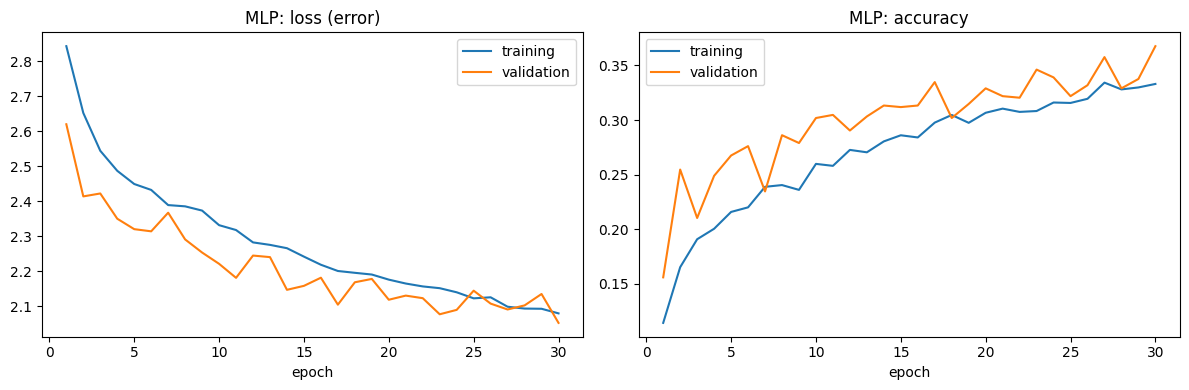

In [13]:
plot_history(history_mlp, "MLP")

## 7. Model 2: a simple CNN

Now let's build a small CNN:


*   `nn.Conv2d` with only one 3×3 convolution layer. Suck block could help to look at small  neighbourhoods of pixels, so the network can learn local patterns (edges, roofs, roads, field boundaries) wherever they appear in the image.
* `MaxPool2d(2)` halves the image size: 32 → 16. Take a guess why we need that?
* `nn.Linear`- based classifier then makes the decision.

In [14]:
seed_everything()
cnn = nn.Sequential(
    # feature extraction
    nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(),   # (3, 32, 32)  -> (32, 32, 32)
    nn.MaxPool2d(2),                                         # (32, 32, 32) -> (32, 16, 16)
    # classification
    nn.Flatten(),                                            # (32, 16, 16) -> 32 * 16 * 16 = 8192
    nn.Linear(32 * (IMG_SIZE // 2) ** 2, 128), nn.ReLU(),
    nn.Linear(128, NUM_CLASSES),
)
print(cnn)
print("trainable parameters:", count_parameters(cnn))

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Flatten(start_dim=1, end_dim=-1)
  (4): Linear(in_features=8192, out_features=128, bias=True)
  (5): ReLU()
  (6): Linear(in_features=128, out_features=20, bias=True)
)
trainable parameters: 1052180


In [15]:
history_cnn = train_model(cnn, "CNN")

CNN | epoch  1 | train loss 2.739 | val loss 2.435 | train acc 0.141 | val acc 0.246
CNN | epoch  5 | train loss 1.962 | val loss 1.898 | train acc 0.359 | val acc 0.388
CNN | epoch 10 | train loss 1.746 | val loss 1.701 | train acc 0.440 | val acc 0.455
CNN | epoch 15 | train loss 1.556 | val loss 1.598 | train acc 0.501 | val acc 0.495
CNN | epoch 20 | train loss 1.448 | val loss 1.475 | train acc 0.533 | val acc 0.528
CNN | epoch 25 | train loss 1.364 | val loss 1.429 | train acc 0.561 | val acc 0.548
CNN | epoch 30 | train loss 1.291 | val loss 1.430 | train acc 0.586 | val acc 0.544
CNN: best validation accuracy 0.549


**Loss and accuracy of the CNN.** Compare them with the MLP graphs above.

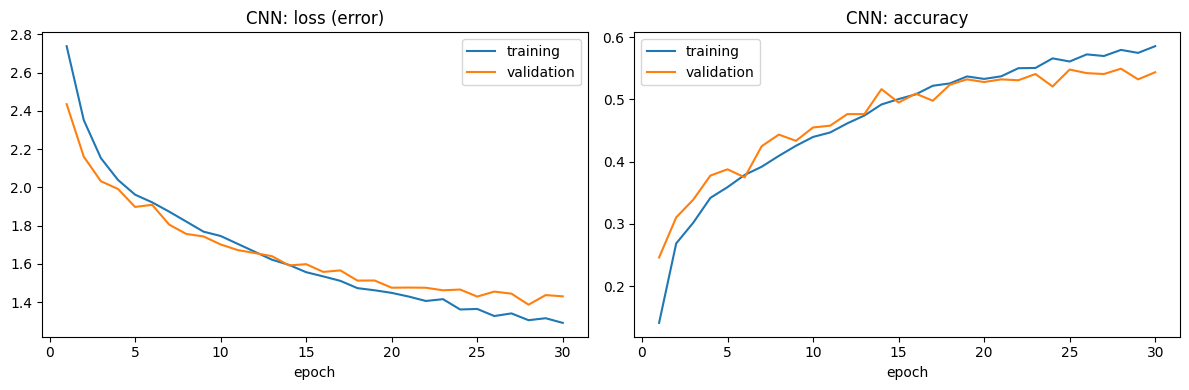

In [16]:
plot_history(history_cnn, "CNN")

## 8. Compare the models
Note that the CNN has **fewer parameters** than the MLP, but still it performs much better, even with only one convolution layer.

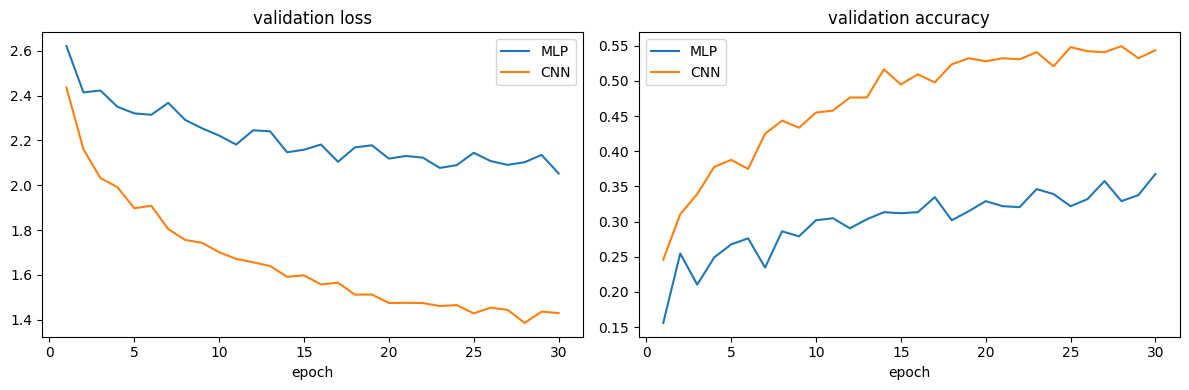

model  parameters  best val accuracy
  MLP     1709844              0.368
  CNN     1052180              0.549


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for history, name in [(history_mlp, "MLP"), (history_cnn, "CNN")]:
    axes[0].plot(history.epoch, history.val_loss, label=name)
    axes[1].plot(history.epoch, history.val_acc, label=name)
axes[0].set_title("validation loss"); axes[1].set_title("validation accuracy")
for ax in axes: ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

results = pd.DataFrame({
    "model": ["MLP", "CNN"],
    "parameters": [count_parameters(mlp), count_parameters(cnn)],
    "best val accuracy": [history_mlp.val_acc.max(), history_cnn.val_acc.max()],
})
print(results.round(3).to_string(index=False))

Take your time and make experiments with different combinations and design your own CNN. Don't forget to use such technics as:

- [Dropout](https://docs.pytorch.org/docs/2.14/generated/torch.nn.modules.dropout.Dropout.html#dropout$0)
- [Batch normalization](https://docs.pytorch.org/docs/2.14/generated/torch.nn.BatchNorm2d.html)

Also don't forget to add more convolution layers as it allows to construct more and more complex features for your model.

In [18]:
seed_everything()
advanced_cnn = nn.Sequential(
    # block 1: 32x32 -> 16x16
    nn.Conv2d(3, 48, kernel_size=3, padding=1), nn.BatchNorm2d(48), nn.ReLU(),
    nn.Conv2d(48, 48, kernel_size=3, padding=1), nn.BatchNorm2d(48), nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Dropout(0.1),

    # block 2: 16x16 -> 8x8
    nn.Conv2d(48, 96, kernel_size=3, padding=1), nn.BatchNorm2d(96), nn.ReLU(),
    nn.Conv2d(96, 96, kernel_size=3, padding=1), nn.BatchNorm2d(96), nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Dropout(0.1),

    # block 3: 8x8 -> 4x4
    nn.Conv2d(96, 192, kernel_size=3, padding=1), nn.BatchNorm2d(192), nn.ReLU(),
    nn.Conv2d(192, 192, kernel_size=3, padding=1), nn.BatchNorm2d(192), nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Dropout(0.2),

    # classification
    nn.AdaptiveAvgPool2d(1),        # average over the 4x4 map -> 192 numbers per image
    nn.Flatten(),
    nn.Linear(192, 128), nn.ReLU(), nn.Dropout(0.4),
    nn.Linear(128, NUM_CLASSES),
)
print(advanced_cnn)
print("trainable parameters:", count_parameters(advanced_cnn))

Sequential(
  (0): Conv2d(3, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (5): ReLU()
  (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (7): Dropout(p=0.1, inplace=False)
  (8): Conv2d(48, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (12): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (15): Dropout(p=0.1, inplace=False)
  (16): Conv2d(96, 192, kernel_size=(3, 3), strid

Advanced CNN | epoch  1 | train loss 2.514 | val loss 2.206 | train acc 0.209 | val acc 0.292
Advanced CNN | epoch  5 | train loss 1.843 | val loss 1.880 | train acc 0.388 | val acc 0.403
Advanced CNN | epoch 10 | train loss 1.415 | val loss 1.544 | train acc 0.537 | val acc 0.504
Advanced CNN | epoch 15 | train loss 1.177 | val loss 1.076 | train acc 0.611 | val acc 0.638
Advanced CNN | epoch 20 | train loss 1.037 | val loss 1.082 | train acc 0.662 | val acc 0.654
Advanced CNN | epoch 25 | train loss 0.904 | val loss 1.393 | train acc 0.702 | val acc 0.594
Advanced CNN | epoch 30 | train loss 0.828 | val loss 0.864 | train acc 0.730 | val acc 0.714
Advanced CNN | epoch 35 | train loss 0.762 | val loss 0.914 | train acc 0.742 | val acc 0.708
Advanced CNN | epoch 40 | train loss 0.666 | val loss 0.809 | train acc 0.774 | val acc 0.721
Advanced CNN: best validation accuracy 0.740


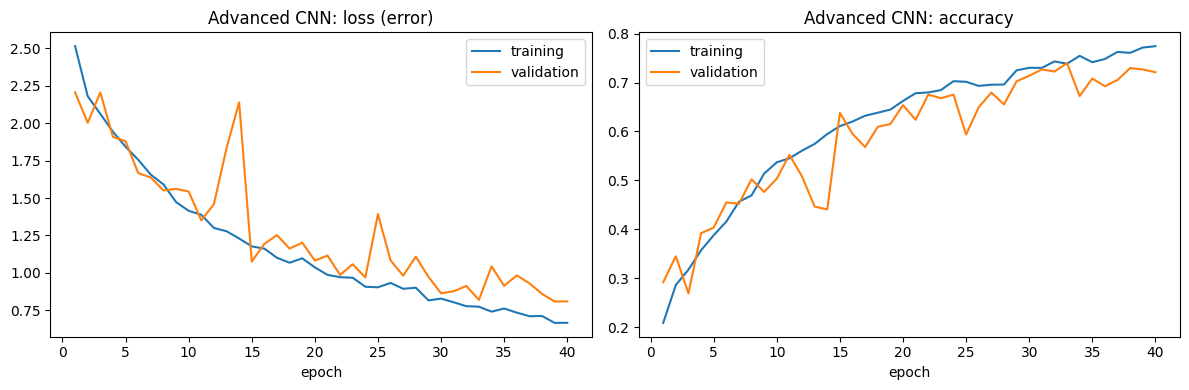

In [19]:
history_adv = train_model(advanced_cnn, "Advanced CNN", epochs=40)
plot_history(history_adv, "Advanced CNN")

## 9. Predict the test images and create `submission.csv`
It's up to you what model to use for the submission. We use the model with the best validation accuracy. The submission needs one row per test image: the `id` exactly
as in `test.csv` (e.g. `1000.jpg`) and the predicted `label`.

In [20]:
best_name = results.sort_values("best val accuracy").model.iloc[-1]
best_model = {"MLP": mlp, "CNN": cnn}[best_name]

submission = pd.DataFrame({"id": test_set.ids, "label": predict(best_model, test_set)})

# format check before uploading
assert list(submission.columns) == ["id", "label"]
assert submission.id.tolist() == test_table.id.tolist()
assert submission.label.between(0, NUM_CLASSES - 1).all()

submission.to_csv("submission.csv", index=False)
print("model used:", best_name, "| rows:", len(submission))
submission.head()

model used: CNN | rows: 8299


,id,label
0,2.jpg,4
1,4.jpg,5
2,5.jpg,10
3,7.jpg,18
4,8.jpg,7


## 10. Upload to Kaggle
Download `submission.csv` to your own computer (Colab: the cell below; Kaggle notebook: the *Output* panel) and
upload it on the competition page with *Submit Prediction* (will be opened on **Saturday 3th of October**).


---
## 11. Assignment: pretrained models and a confusion matrix

Networks pretrained on ImageNet (1.2 million photos, 1,000 classes) have already learned general visual features:
edges, textures, shapes. We can reuse them and train only a small part for our 20 classes.

**Allowed architectures** (no Transformers and no other families):

| Family | torchvision constructors | Final layer to replace |
|---|---|---|
| AlexNet | `alexnet` | `model.classifier` (last layer: `model.classifier[6]`) |
| VGG | `vgg11`, `vgg13`, `vgg16`, `vgg19` (also `_bn` versions) | `model.classifier` (last layer: `model.classifier[6]`) |
| Inception | `googlenet`, `inception_v3` | `model.fc` |
| ResNet | `resnet18`, `resnet34`, `resnet50`, `resnet101`, `resnet152` | `model.fc` |

### Example: how to prepare a pretrained model
The example below only **prepares** a pretrained ResNet-18. It shows four steps:
1. load the model with pretrained weights;
2. **freeze** all its weights (`requires_grad = False`), so training doesn't change them;
3. **unfreeze** the last block (`requires_grad = True`), so it can adapt to aerial images;
4. remove the original 1,000-class classifier and combine the network with **our own classifier** using `nn.Sequential`.

In [21]:
# 1) load ResNet-18 with weights pretrained on ImageNet
backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
print(backbone)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 194MB/s]

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [22]:
# 2) freeze all pretrained weights
for param in backbone.parameters():
    param.requires_grad = False

# 3) unfreeze the last residual block, so it can be retrained
for param in backbone.layer4.parameters():
    param.requires_grad = True

# check which parts will be trained
for name, param in backbone.named_parameters():
    if param.requires_grad:
        print("trainable:", name)

trainable: layer4.0.conv1.weight
trainable: layer4.0.bn1.weight
trainable: layer4.0.bn1.bias
trainable: layer4.0.conv2.weight
trainable: layer4.0.bn2.weight
trainable: layer4.0.bn2.bias
trainable: layer4.0.downsample.0.weight
trainable: layer4.0.downsample.1.weight
trainable: layer4.0.downsample.1.bias
trainable: layer4.1.conv1.weight
trainable: layer4.1.bn1.weight
trainable: layer4.1.bn1.bias
trainable: layer4.1.conv2.weight
trainable: layer4.1.bn2.weight
trainable: layer4.1.bn2.bias


In [23]:
# 4) replace the original classifier by our own and combine both with nn.Sequential
num_features = backbone.fc.in_features          # 512 for ResNet-18
backbone.fc = nn.Identity()                     # the backbone now outputs 512 features per image

classifier = nn.Sequential(
    nn.Linear(num_features, 256),
    nn.LeakyReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, NUM_CLASSES),                # no softmax: nn.CrossEntropyLoss applies it
)

pretrained_model = nn.Sequential(backbone, classifier)

print(classifier)
print("trainable parameters:", count_parameters(pretrained_model),
      "of", sum(p.numel() for p in pretrained_model.parameters()))

# quick check: a batch of 2 images of size 224x224 gives 2 x 20 class scores
print("output shape:", tuple(pretrained_model(torch.randn(2, 3, 224, 224)).shape))

Sequential(
  (0): Linear(in_features=512, out_features=256, bias=True)
  (1): LeakyReLU(negative_slope=0.01)
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=256, out_features=20, bias=True)
)
trainable parameters: 8530196 of 11312980
output shape: (2, 20)


### Your tasks
1. **Train a pretrained model** from the allowed list. Prepare it as in the example (your own classifier combined
   with `nn.Sequential`, at least one pretrained layer or block unfrozen) and train it with `train_model`.
2. **Adapt the data pipeline.** Pretrained models expect larger images and ImageNet normalisation: think about
   `IMG_SIZE` (e.g. 128 or 224; `inception_v3` needs 299), `Normalize` with ImageNet mean and std, and which
   augmentations help. You'll need new `transforms.Compose` pipelines and new `ContestDataset` objects.
3. **Compare** your pretrained model with the MLP and the Advanced CNN you have designed previously: a table of validation accuracy and the loss and
   accuracy graphs (`plot_history`).
4. **Confusion matrix.** Make a confusion matrix of your best model on the validation set (rows = true class,
   columns = predicted class, with class names on the axes). Which classes are confused most often, and why might
   that be? Look at a few of the misclassified images.
   *Hint:* `predict(model, val_set)` gives the predictions, `val_set.labels` the true classes;
   see `sklearn.metrics.confusion_matrix` and `ConfusionMatrixDisplay`. But it's up to you how to implement it.
5. **Experiment and explain:** which layers to unfreeze, learning rate, augmentations, image size. Which change had the biggest effect on the validation accuracy, and why?
6. **Submit** your best model to Kaggle with a short description of what it is.

**Requirements**
* Only AlexNet, VGG, Inception (GoogLeNet / Inception v3) and ResNet; no Transformers, no other architectures.
* Pretrained weights only from torchvision (ImageNet).
* Your own classification layers, combined with the pretrained network via `nn.Sequential`.
* No external data; the notebook runs end to end with a fixed `SEED` and reproduces your score.

## 12. Solution: pretrained ResNet-50 + Inception-v3

### Step 1. Compare training images with validation and test images
The task says that satellite images can have artifacts: blur, low resolution, colour changes. Let's check if the
validation and test images are different from the training images. For every image we measure:
* **brightness** - mean pixel value;
* **saturation** - how colourful the image is;
* **sharpness** - variance of the Laplacian (a small value means a blurry image);
* **grayscale** - is the image black and white.

In [24]:
import time
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


def measure_image(path):
    image = Image.open(path).convert("RGB")
    pixels = np.array(image, dtype=np.float32) / 255
    gray = np.array(image.convert("L"), dtype=np.float32)
    saturation = np.array(image.convert("HSV"), dtype=np.float32)[:, :, 1] / 255

    # Laplacian: 4 * pixel - (up + down + left + right)
    laplacian = (4 * gray[1:-1, 1:-1] - gray[:-2, 1:-1] - gray[2:, 1:-1]
                 - gray[1:-1, :-2] - gray[1:-1, 2:])

    red_minus_green = np.abs(pixels[:, :, 0] - pixels[:, :, 1]).mean()
    is_grayscale = red_minus_green < 0.01

    return {
        "brightness": pixels.mean(),
        "saturation": saturation.mean(),
        "sharpness": laplacian.var(),
        "grayscale": is_grayscale,
    }


image_measurements = {}
for folder, table in [("train", train_table), ("val", val_table), ("test", test_table)]:
    rows = []
    for image_id in table.id.sample(400, random_state=SEED):
        rows.append(measure_image(DATA_DIR / folder / image_id))
    image_measurements[folder] = pd.DataFrame(rows)

summary = {}
for folder in image_measurements:
    measurements = image_measurements[folder]
    summary[folder] = {
        "median brightness": measurements.brightness.median(),
        "median saturation": measurements.saturation.median(),
        "median sharpness": measurements.sharpness.median(),
        "10% most blurry: sharpness below": measurements.sharpness.quantile(0.1),
        "share of grayscale images": measurements.grayscale.mean(),
    }
summary = pd.DataFrame(summary)
print(summary.round(3))

                                    train      val     test
median brightness                   0.329    0.329    0.331
median saturation                   0.190    0.184    0.189
median sharpness                  738.213  563.240  554.165
10% most blurry: sharpness below  153.617   32.805   29.496
share of grayscale images           0.035    0.082    0.080


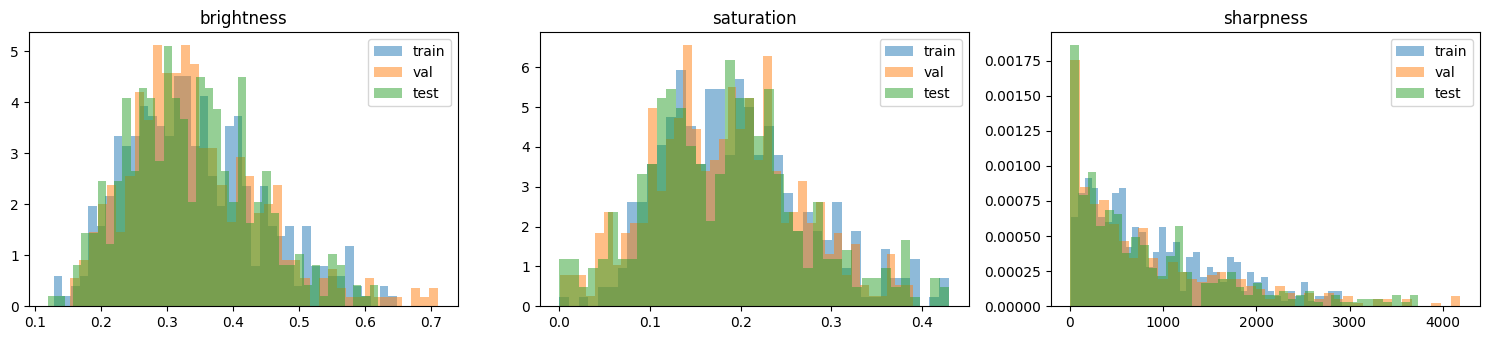

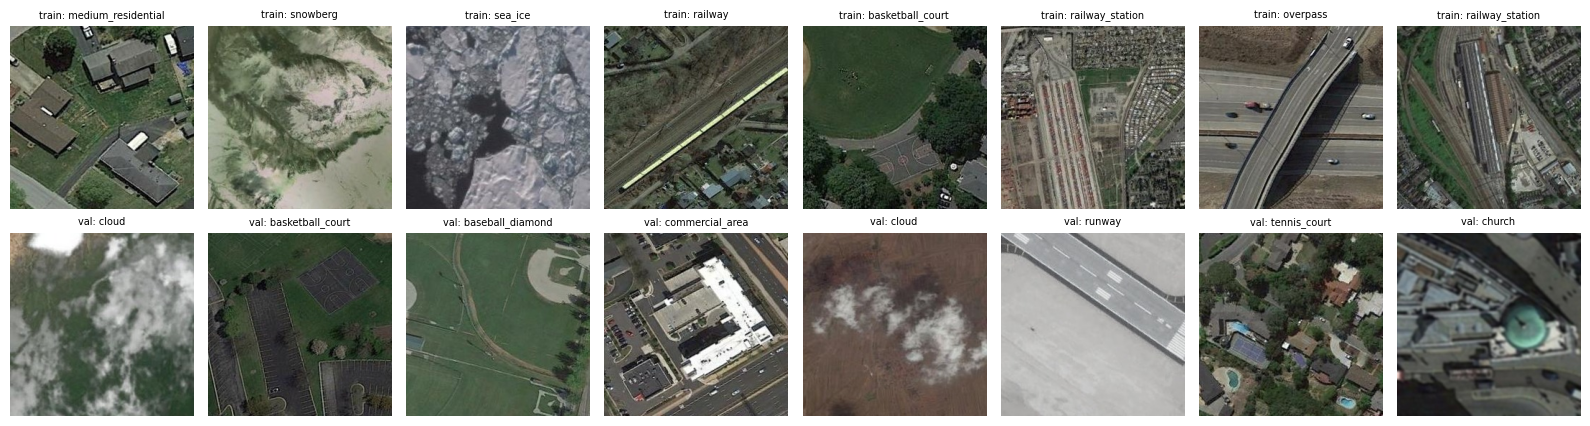

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, column in zip(axes, ["brightness", "saturation", "sharpness"]):
    for folder in image_measurements:
        values = image_measurements[folder][column]
        values = values[values < values.quantile(0.98)]     # cut extreme values to make the plot readable
        ax.hist(values, bins=40, alpha=0.5, density=True, label=folder)
    ax.set_title(column)
    ax.legend()
plt.tight_layout(); plt.show()

# random training images (top row) and validation images (bottom row)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for row, (folder, table) in enumerate([("train", train_table), ("val", val_table)]):
    examples = table.sample(8, random_state=1)
    for ax, image_id, label in zip(axes[row], examples.id, examples.label):
        ax.imshow(Image.open(DATA_DIR / folder / image_id))
        ax.set_title(f"{folder}: {classes[label]}", fontsize=7)
        ax.axis("off")
plt.tight_layout(); plt.show()

**What we see:** brightness and saturation are almost the same in all three sets, but the validation/test
images are different in two ways:
* about 8% of them are grayscale (3.5% in train);
* many of them are much more blurry: the 10% most blurry validation/test images have sharpness below ~30,
  in train below ~150, so they are about 5 times more blurry than anything in train.

The model has never seen such images, so we have to create them ourselves with augmentations.

In [26]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


class RotateBy90:
    """Rotate the image by 0, 90, 180 or 270 degrees."""
    def __call__(self, image):
        angle = random.choice([0, 90, 180, 270])
        return image.rotate(angle)


class LowResolution:
    """Make the image 2-8 times smaller and then stretch it back."""
    def __call__(self, image):
        factor = random.uniform(2, 8)
        width, height = image.size
        small_image = image.resize((int(width / factor), int(height / factor)), Image.BILINEAR)
        return small_image.resize((width, height), Image.BILINEAR)


class AddNoise:
    """Add random noise to an image tensor (values 0...1)."""
    def __call__(self, image_tensor):
        noise = torch.randn_like(image_tensor) * 0.03
        return (image_tensor + noise).clamp(0, 1)


def get_train_transform(image_size):
    return transforms.Compose([
        transforms.RandomResizedCrop(image_size, scale=(0.45, 1.0)),
        RotateBy90(),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomApply([transforms.ColorJitter(0.35, 0.35, 0.35, 0.06)], p=0.8),
        transforms.RandomGrayscale(p=0.15),
        transforms.RandomApply([LowResolution()], p=0.2),
        transforms.RandomApply([transforms.GaussianBlur(15, sigma=(0.5, 4.0))], p=0.2),
        transforms.ToTensor(),
        transforms.RandomApply([AddNoise()], p=0.15),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        transforms.RandomErasing(p=0.25, scale=(0.02, 0.15)),
    ])


def get_test_transform(image_size):
    return transforms.Compose([
        transforms.Resize(image_size),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])

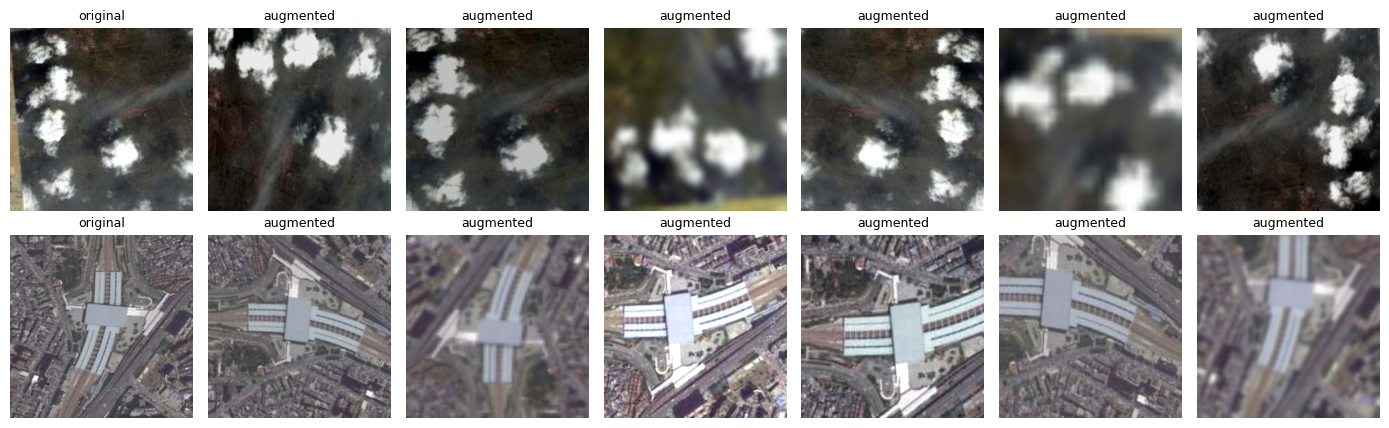

In [27]:
# what the augmentations do: the original image and 6 augmented versions
show_augmentations = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.45, 1.0)),
    RotateBy90(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([transforms.ColorJitter(0.35, 0.35, 0.35, 0.06)], p=0.8),
    transforms.RandomGrayscale(p=0.15),
    transforms.RandomApply([LowResolution()], p=0.2),
    transforms.RandomApply([transforms.GaussianBlur(15, sigma=(0.5, 4.0))], p=0.2),
])

fig, axes = plt.subplots(2, 7, figsize=(14, 4.4))
for row in range(2):
    image = Image.open(DATA_DIR / "train" / train_table.id[row]).convert("RGB")
    axes[row, 0].imshow(image)
    axes[row, 0].set_title("original", fontsize=9)
    for column in range(1, 7):
        axes[row, column].imshow(show_augmentations(image))
        axes[row, column].set_title("augmented", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.show()

### Step 3. Dataset with full-size images
This time we use the images in their original size (256x256). Each model resizes them to the size it needs:
224 for ResNet, 299 for Inception-v3. That's why the transform is not fixed in the dataset: we set
`dataset.transform` before training or predicting.

The images are read from the disk every time they are needed. Keeping ~14,000 full-size images in memory
takes ~5 GB and doesn't fit in the Colab RAM together with everything else.

In [28]:
class SatelliteDataset(Dataset):
    def __init__(self, image_paths, labels):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = None

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = Image.open(self.image_paths[index]).convert("RGB")
        image = self.transform(image)
        return image, self.labels[index]


train_paths = [DATA_DIR / "train" / image_id for image_id in train_table.id]
val_paths = [DATA_DIR / "val" / image_id for image_id in val_table.id]
test_paths = [DATA_DIR / "test" / image_id for image_id in test_table.id]

train_labels = list(train_table.label)
val_labels = list(val_table.label)
test_labels = [-1] * len(test_table)            # we don't know the test labels

big_train_set = SatelliteDataset(train_paths, train_labels)
big_val_set = SatelliteDataset(val_paths, val_labels)
big_test_set = SatelliteDataset(test_paths, test_labels)
print(len(big_train_set), len(big_val_set), len(big_test_set))

4999 699 8299


### Step 4. Pretrained model with our own classifier
The same steps as in the example above:
1. load the model with ImageNet weights;
2. freeze all layers;
3. unfreeze the layers starting from `first_trainable_block` (the first layers find simple things like edges,
   they are useful as they are);
4. replace the last layer `fc` by our own classifier and join them with `nn.Sequential`.

Inception-v3 has an extra small classifier in the middle of the network (`AuxLogits`); we don't need it.

In [29]:
def create_model(model_name):
    if model_name == "resnet50":
        network = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        image_size = 224
        first_trainable_block = "layer2"
    elif model_name == "inception_v3":
        network = models.inception_v3(weights=models.Inception_V3_Weights.IMAGENET1K_V1)
        network.aux_logits = False
        network.AuxLogits = None
        image_size = 299
        first_trainable_block = "Mixed_5b"
    else:
        raise ValueError("unknown model: " + model_name)

    # freeze everything
    for parameter in network.parameters():
        parameter.requires_grad = False

    # unfreeze the blocks starting from first_trainable_block
    unfreeze = False
    for block_name, block in network.named_children():
        if block_name == first_trainable_block:
            unfreeze = True
        if unfreeze:
            for parameter in block.parameters():
                parameter.requires_grad = True

    # our own classifier instead of the old 1000-class layer
    number_of_features = network.fc.in_features
    network.fc = nn.Identity()
    classifier = nn.Sequential(
        nn.Dropout(0.3),
        nn.Linear(number_of_features, 512),
        nn.BatchNorm1d(512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, NUM_CLASSES),
    )

    model = nn.Sequential(network, classifier)
    return model, image_size


for model_name in ["resnet50", "inception_v3"]:
    model, image_size = create_model(model_name)
    total = sum(p.numel() for p in model.parameters())
    print(f"{model_name}: image size {image_size}, trainable parameters {count_parameters(model):,} of {total:,}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 176MB/s]


resnet50: image size 224, trainable parameters 24,343,060 of 24,568,404
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 153MB/s]


inception_v3: image size 299, trainable parameters 22,673,268 of 22,845,940


### Step 5. Training and prediction
The training loop is like `train_model` above, with a few changes:
* **two learning rates:** the pretrained layers get a 10 times smaller learning rate than our new classifier,
  so we don't destroy what they already learned;
* **cosine schedule:** the learning rate slowly goes down to zero by the last epoch, so we simply keep the
  weights of the last epoch;
* **label smoothing:** the model is not pushed to be 100% sure, which helps with a small dataset;
* **mixed precision** on a CUDA GPU: faster training.

**Test-time augmentation (TTA):** to predict an image we show the model 8 versions of it (4 rotations, each also
flipped) and average the 8 answers.

In [30]:
# number of epochs for every model, chosen so that training of both models takes ~45 minutes on a Colab T4
# (ResNet-50: ~1 min per epoch, Inception-v3: ~1.6 min per epoch)
EPOCHS_PER_MODEL = {"resnet50": 20, "inception_v3": 16}
PRETRAINED_BATCH_SIZE = 32
LEARNING_RATE = 1e-3
USE_AMP = DEVICE == "cuda"                  # mixed precision works only on a CUDA GPU
if DEVICE != "cuda":
    print("No GPU! In Colab choose Runtime -> Change runtime type -> T4 GPU, otherwise training takes hours.")
if DEVICE == "cuda":
    NUM_WORKERS = 2                         # prepare batches in parallel (Colab)
else:
    NUM_WORKERS = 0                         # on macOS workers can't use classes defined in a notebook


def get_eight_versions(images):
    """4 rotations of a batch of images, and each of them also flipped."""
    versions = []
    for k in range(4):
        rotated = torch.rot90(images, k, dims=(2, 3))
        versions.append(rotated)
        versions.append(rotated.flip(3))
    return versions


def predict_probabilities(model, dataset, image_size, use_tta=True):
    dataset.transform = get_test_transform(image_size)
    data_loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=NUM_WORKERS)
    model.eval()
    all_probabilities = []
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(DEVICE)
            if use_tta:
                versions = get_eight_versions(images)
            else:
                versions = [images]

            probabilities = torch.zeros(len(images), NUM_CLASSES, device=DEVICE)
            for version in versions:
                with torch.autocast(device_type="cuda", enabled=USE_AMP):
                    outputs = model(version)
                probabilities += torch.softmax(outputs.float(), dim=1)
            probabilities = probabilities / len(versions)
            all_probabilities.append(probabilities.cpu())
    return torch.cat(all_probabilities).numpy()


def accuracy_and_loss(probabilities, labels):
    labels = np.array(labels)
    accuracy = (probabilities.argmax(axis=1) == labels).mean()
    probability_of_true_class = probabilities[np.arange(len(labels)), labels]
    loss = -np.log(probability_of_true_class + 1e-8).mean()
    return accuracy, loss


def train_pretrained_model(model_name, train_dataset, val_dataset=None):
    start_time = time.time()
    epochs = EPOCHS_PER_MODEL[model_name]
    seed_everything()
    model, image_size = create_model(model_name)
    model = model.to(DEVICE)
    train_dataset.transform = get_train_transform(image_size)

    network, classifier = model[0], model[1]
    pretrained_parameters = []
    for parameter in network.parameters():
        if parameter.requires_grad:
            pretrained_parameters.append(parameter)

    optimizer = torch.optim.AdamW([
        {"params": pretrained_parameters, "lr": LEARNING_RATE / 10},
        {"params": classifier.parameters(), "lr": LEARNING_RATE},
    ], weight_decay=0.02)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    loss_function = nn.CrossEntropyLoss(label_smoothing=0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    train_loader = DataLoader(train_dataset, batch_size=PRETRAINED_BATCH_SIZE, shuffle=True,
                              drop_last=True, num_workers=NUM_WORKERS,
                              generator=torch.Generator().manual_seed(SEED))

    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0
        correct = 0
        seen = 0
        for images, labels in tqdm(train_loader, desc=f"{model_name}, epoch {epoch}", leave=False):
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()
            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                outputs = model(images)
                loss = loss_function(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            total_loss += loss.item() * len(images)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            seen += len(images)
        scheduler.step()

        epoch_result = {"epoch": epoch, "train_loss": total_loss / seen, "train_acc": correct / seen}
        if val_dataset is not None:
            val_probabilities = predict_probabilities(model, val_dataset, image_size, use_tta=False)
            val_accuracy, val_loss = accuracy_and_loss(val_probabilities, val_dataset.labels)
            epoch_result["val_loss"] = val_loss
            epoch_result["val_acc"] = val_accuracy
        history.append(epoch_result)
        minutes = (time.time() - start_time) / 60
        if val_dataset is not None:
            print(f"{model_name} | epoch {epoch:2d} | train loss {epoch_result['train_loss']:.3f} | "
                  f"val loss {val_loss:.3f} | train acc {epoch_result['train_acc']:.3f} | val acc {val_accuracy:.3f} | "
                  f"{minutes:.1f} min")
        else:
            print(f"{model_name} | epoch {epoch:2d} | train loss {epoch_result['train_loss']:.3f} | "
                  f"train acc {epoch_result['train_acc']:.3f} | {minutes:.1f} min")

    print(f"{model_name} trained in {minutes:.1f} minutes")
    return model, image_size, pd.DataFrame(history)

### Step 6. Train both models and compare everything on the validation set
On a Colab T4 GPU this takes about 45 minutes: ~20 min for ResNet-50 and ~25 min for Inception-v3.

resnet50, epoch 1:   0%|          | 0/156 [00:00<?, ?it/s]

resnet50 | epoch  1 | train loss 1.589 | val loss 0.467 | train acc 0.632 | val acc 0.878 | 0.9 min


resnet50, epoch 2:   0%|          | 0/156 [00:00<?, ?it/s]

resnet50 | epoch  2 | train loss 1.160 | val loss 0.356 | train acc 0.793 | val acc 0.917 | 1.8 min


resnet50, epoch 3:   0%|          | 0/156 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bd4de5f8c20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bd4de5f8c20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

resnet50 | epoch 19 | train loss 0.768 | val loss 0.243 | train acc 0.950 | val acc 0.954 | 18.0 min


resnet50, epoch 20:   0%|          | 0/156 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bd4de5f8c20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bd4de5f8c20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

resnet50 | epoch 20 | train loss 0.774 | val loss 0.238 | train acc 0.947 | val acc 0.953 | 18.9 min
resnet50 trained in 18.9 minutes


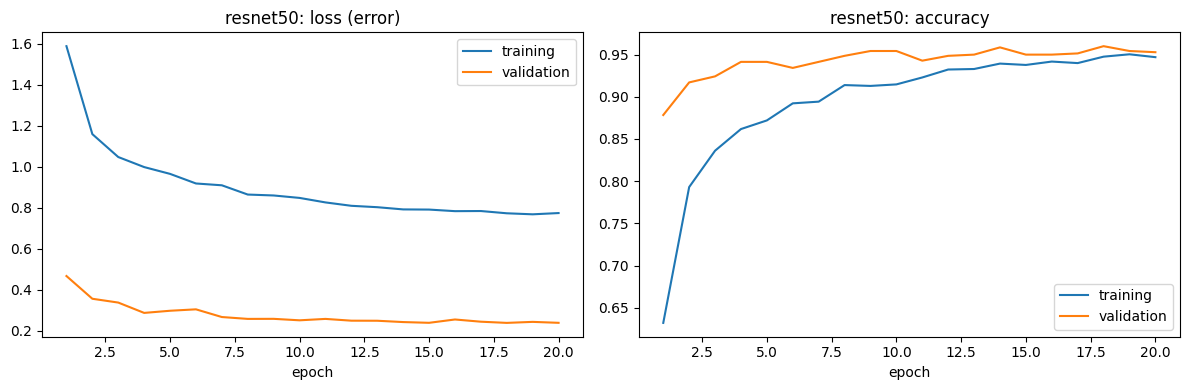

inception_v3, epoch 1:   0%|          | 0/156 [00:00<?, ?it/s]

inception_v3 | epoch  1 | train loss 1.664 | val loss 0.436 | train acc 0.602 | val acc 0.883 | 1.4 min


inception_v3, epoch 2:   0%|          | 0/156 [00:00<?, ?it/s]

inception_v3 | epoch  2 | train loss 1.159 | val loss 0.364 | train acc 0.796 | val acc 0.908 | 2.9 min


inception_v3, epoch 3:   0%|          | 0/156 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bd4de5f8c20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bd4de5f8c20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

inception_v3 | epoch 15 | train loss 0.766 | val loss 0.218 | train acc 0.948 | val acc 0.961 | 22.9 min


inception_v3, epoch 16:   0%|          | 0/156 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bd4de5f8c20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
Exception ignored in: AssertionError<function _MultiProcessingDataLoaderIter.__del__ at 0x7bd4de5f8c20>
: can only test a child processTraceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    self._shutdown_workers()
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
<function _Multi

inception_v3 | epoch 16 | train loss 0.761 | val loss 0.221 | train acc 0.951 | val acc 0.957 | 24.4 min
inception_v3 trained in 24.4 minutes


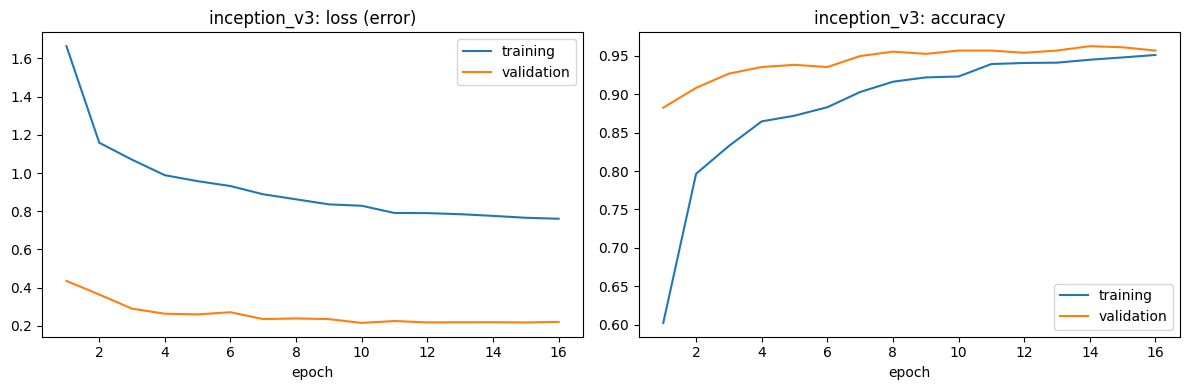

In [31]:
MODEL_NAMES = ["resnet50", "inception_v3"]

trained_models = {}
image_sizes = {}
histories = {}
val_probabilities = {}

for model_name in MODEL_NAMES:
    model, image_size, history = train_pretrained_model(model_name, big_train_set, big_val_set)
    trained_models[model_name] = model
    image_sizes[model_name] = image_size
    histories[model_name] = history
    val_probabilities[model_name] = predict_probabilities(model, big_val_set, image_size, use_tta=True)
    plot_history(history, model_name)

In [32]:
# ensemble = average of the probabilities of both models
ensemble_val_probabilities = np.zeros((len(big_val_set), NUM_CLASSES))
for model_name in MODEL_NAMES:
    ensemble_val_probabilities += val_probabilities[model_name]
ensemble_val_probabilities /= len(MODEL_NAMES)

comparison = []
comparison.append({"model": "MLP", "val accuracy": history_mlp.val_acc.max()})
comparison.append({"model": "simple CNN", "val accuracy": history_cnn.val_acc.max()})
comparison.append({"model": "advanced CNN", "val accuracy": history_adv.val_acc.max()})
for model_name in MODEL_NAMES:
    accuracy_without_tta = histories[model_name].val_acc.iloc[-1]
    accuracy_with_tta, _ = accuracy_and_loss(val_probabilities[model_name], val_labels)
    comparison.append({"model": model_name, "val accuracy": accuracy_without_tta})
    comparison.append({"model": model_name + " + TTA", "val accuracy": accuracy_with_tta})
ensemble_accuracy, _ = accuracy_and_loss(ensemble_val_probabilities, val_labels)
comparison.append({"model": "ensemble of both + TTA", "val accuracy": ensemble_accuracy})

comparison = pd.DataFrame(comparison)
print(comparison.round(4).to_string(index=False))

                 model  val accuracy
                   MLP        0.3677
            simple CNN        0.5494
          advanced CNN        0.7396
              resnet50        0.9528
        resnet50 + TTA        0.9642
          inception_v3        0.9571
    inception_v3 + TTA        0.9671
ensemble of both + TTA        0.9671


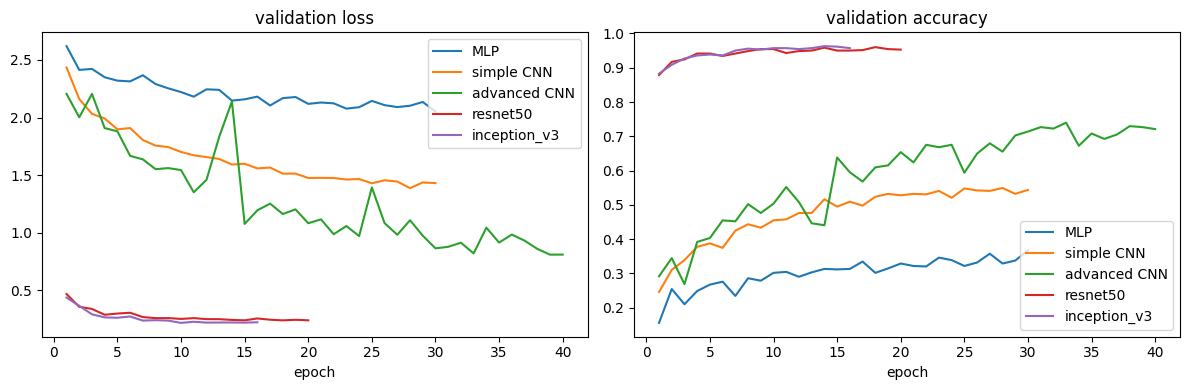

In [33]:
all_histories = {"MLP": history_mlp, "simple CNN": history_cnn, "advanced CNN": history_adv}
for model_name in MODEL_NAMES:
    all_histories[model_name] = histories[model_name]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in all_histories.items():
    axes[0].plot(history.epoch, history.val_loss, label=name)
    axes[1].plot(history.epoch, history.val_acc, label=name)
axes[0].set_title("validation loss")
axes[1].set_title("validation accuracy")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout(); plt.show()

### Step 7. Confusion matrix
Rows are the true classes, columns are the predicted classes (ensemble, validation set).

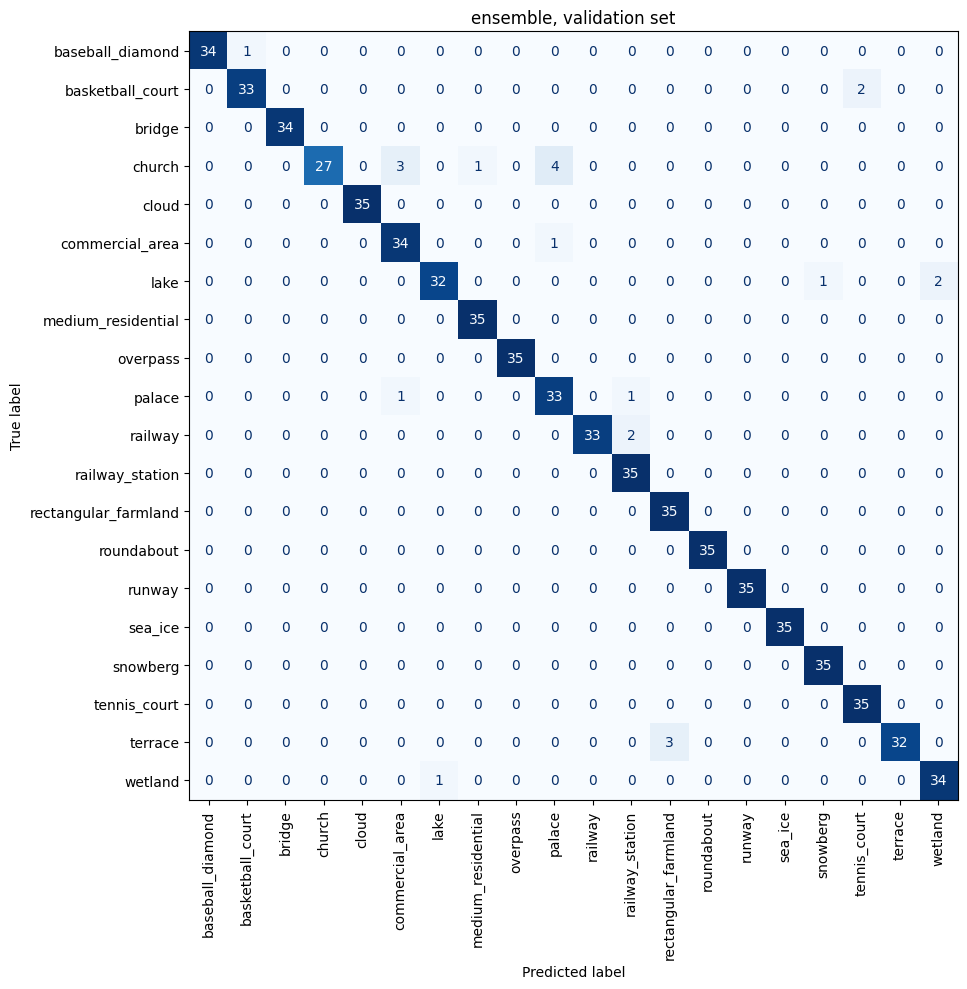

Worst classes:
church              0.771
lake                0.914
terrace             0.914
basketball_court    0.943
railway             0.943
palace              0.943
commercial_area     0.971
baseball_diamond    0.971
dtype: float64

Most common mistakes (count: true class -> predicted class):
4: church -> palace
3: terrace -> rectangular_farmland
3: church -> commercial_area
2: railway -> railway_station
2: lake -> wetland
2: basketball_court -> tennis_court
1: wetland -> lake
1: palace -> railway_station


In [34]:
val_predictions = ensemble_val_probabilities.argmax(axis=1)
matrix = confusion_matrix(val_labels, val_predictions)

fig, ax = plt.subplots(figsize=(11, 10))
ConfusionMatrixDisplay(matrix, display_labels=classes).plot(ax=ax, xticks_rotation=90, colorbar=False, cmap="Blues")
ax.set_title("ensemble, validation set")
plt.tight_layout(); plt.show()

# accuracy of every class
class_accuracy = pd.Series(matrix.diagonal() / matrix.sum(axis=1), index=classes)
print("Worst classes:")
print(class_accuracy.sort_values().head(8).round(3))

# which pairs of classes are confused most often
mistakes = []
for true_class in range(NUM_CLASSES):
    for predicted_class in range(NUM_CLASSES):
        count = matrix[true_class, predicted_class]
        if true_class != predicted_class and count > 0:
            mistakes.append((count, classes[true_class], classes[predicted_class]))
mistakes.sort(reverse=True)
print("\nMost common mistakes (count: true class -> predicted class):")
for count, true_name, predicted_name in mistakes[:8]:
    print(f"{count}: {true_name} -> {predicted_name}")

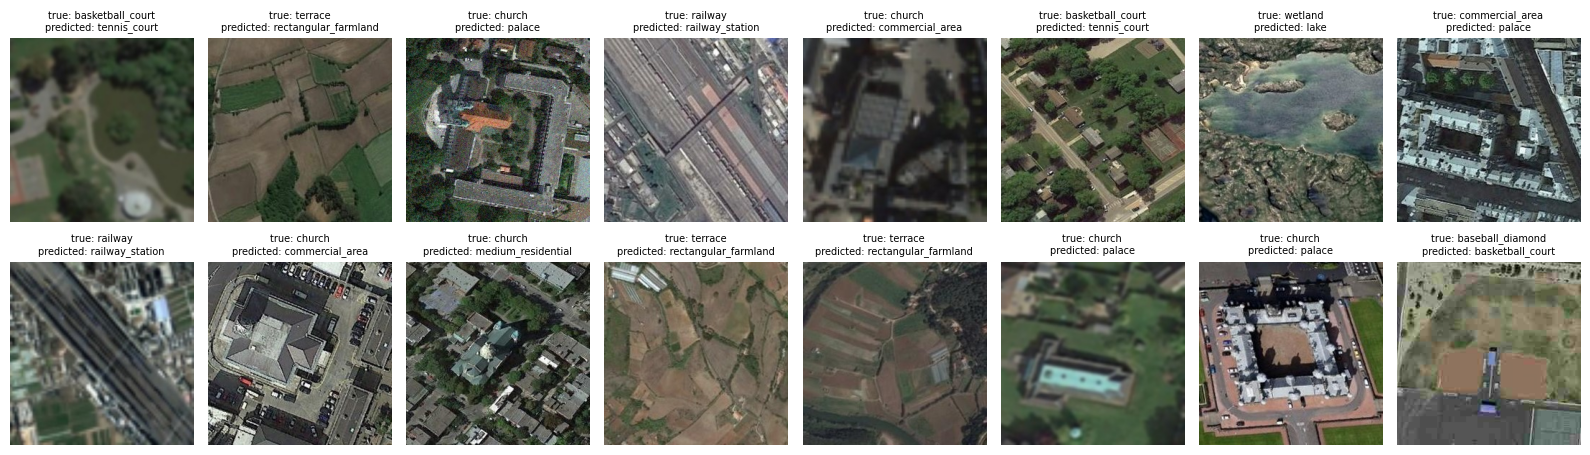

In [35]:
# some of the wrongly classified validation images
wrong_indexes = np.where(val_predictions != np.array(val_labels))[0][:16]

fig, axes = plt.subplots(2, 8, figsize=(16, 4.8))
for ax in axes.flat:
    ax.axis("off")
for ax, index in zip(axes.flat, wrong_indexes):
    ax.imshow(Image.open(val_paths[index]))
    ax.set_title(f"true: {classes[val_labels[index]]}\npredicted: {classes[val_predictions[index]]}", fontsize=7)
plt.tight_layout(); plt.show()

### Step 8. Final models and the submission file
For the submission we use the models from step 6 (ensemble + TTA).

Optionally (`TRAIN_ON_TRAIN_AND_VAL = True`) both models can be trained again on **train + validation** together:
the validation images are similar to the test images, so this usually helps a bit. But it takes another
~50 minutes.

In [36]:
TRAIN_ON_TRAIN_AND_VAL = False
SUBMISSION_FILE = "Aleksandra_Ivanova.csv"
if TRAIN_ON_TRAIN_AND_VAL:
    train_and_val_set = SatelliteDataset(train_paths + val_paths, train_labels + val_labels)
    final_models = {}
    for model_name in MODEL_NAMES:
        model, image_size, history = train_pretrained_model(model_name, train_and_val_set)
        final_models[model_name] = model
else:
    final_models = trained_models

test_probabilities = np.zeros((len(big_test_set), NUM_CLASSES))
for model_name in MODEL_NAMES:
    test_probabilities += predict_probabilities(final_models[model_name], big_test_set, image_sizes[model_name])
test_predictions = test_probabilities.argmax(axis=1)

submission = pd.DataFrame({"id": test_table.id, "label": test_predictions})

# format check before uploading
assert list(submission.columns) == ["id", "label"]
assert len(submission) == len(test_table)
assert submission.label.between(0, NUM_CLASSES - 1).all()

submission.to_csv(SUBMISSION_FILE, index=False)
print("saved", SUBMISSION_FILE, "with", len(submission), "rows")
submission.head()

saved Name_Surname.csv with 8299 rows


,id,label
0,2.jpg,4
1,4.jpg,9
2,5.jpg,11
3,7.jpg,18
4,8.jpg,10


In [37]:
# Colab: download the file to your computer
try:
    from google.colab import files
    files.download(SUBMISSION_FILE)
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Experiments and conclusions

**Comparison of the models** (validation set, 699 images):

| Model | Image size | Val accuracy | Training time (Colab T4) |
|---|---|---|---|
| MLP | 32 px | 0.368 | |
| simple CNN | 32 px | 0.549 | |
| advanced CNN (6 conv layers, BatchNorm, Dropout) | 32 px | 0.740 | |
| ResNet-50, layers 2-4 unfrozen, 20 epochs | 224 px | 0.953 | 18.9 min |
| ResNet-50 + TTA | 224 px | 0.964 | |
| Inception-v3, from Mixed_5b unfrozen, 16 epochs | 299 px | 0.957 | 24.4 min |
| Inception-v3 + TTA | 299 px | 0.967 | |
| **ensemble ResNet-50 + Inception-v3 + TTA** (submitted) | | **0.967** | 43.3 min in total |

**Confusion matrix: which classes are confused and why**
* `church -> palace` (4) and `church -> commercial_area` (3): church is the worst class (0.77). From above a
  church is just a big building with a complex roof in a city, the same as a palace or an office block.
  There is no tower or cross visible from above.
* `terrace -> rectangular_farmland` (3): both are fields divided into long stripes; terraces just follow the
  shape of a hill.
* `lake -> wetland` (2) and `wetland -> lake` (1): both are water with vegetation; where a lake ends and a
  wetland begins is not clear even for a human.
* `railway -> railway_station` (2): a station is railway tracks plus a building, so a picture with many tracks
  and a small building fits both.
* `basketball_court -> tennis_court` (2): both are small rectangular courts with lines; after blurring the
  lines look the same.

Many of the wrong images in the plot above are blurry or grayscale, so the artifacts are still the main
source of errors.

**What had the biggest effect**
1. **Pretrained model + full image size** (0.740 -> 0.953): the biggest jump. ImageNet features (edges,
   textures, shapes) are already learned, and at 224/299 px small objects like courts and railways are
   actually visible. At 32 px they are a few pixels.
2. **BatchNorm, Dropout and more conv layers** in our own CNN (0.549 -> 0.740): deeper network learns more
   complex patterns; BatchNorm makes training stable, Dropout reduces overfitting.
3. **TTA** (+1.1% for ResNet-50, +1.0% for Inception-v3): an aerial image looks fine after any rotation or
   flip, so averaging 8 versions removes some random mistakes.
4. **Ensemble**: the same accuracy as the best single model with TTA (0.967) on validation, but two different
   architectures make the prediction more stable on the bigger test set.

**Other settings we used** (not compared separately because of the time limit): unfreezing everything except
the first layers, a 10 times smaller learning rate for the pretrained part, cosine learning rate schedule,
label smoothing, and augmentations copying the validation/test artifacts (grayscale, blur, low resolution).
Without the last ones the model would see blurry and grayscale images only at test time.

Both models reach ~0.94 on validation already after 4-5 epochs; the remaining epochs add ~2%.
The validation loss does not go up at the end, so there is no overfitting.